# Phase transitions in the Heisenberg model

In [39]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice

using Random: MersenneTwister
using Statistics: mean, std

    Updating registry at `~/.julia/registries/General.toml`
    Updating git-repo `/home/igor/Physics/MX2-RKKY/MX2RKKY.git`
   Installed Adapt ─────────────── v4.2.0
   Installed OrderedCollections ── v1.8.0
   Installed PyPlot ────────────── v2.11.6
   Installed ColorTypes ────────── v0.12.0
   Installed Colors ────────────── v0.13.0
   Installed IrrationalConstants ─ v0.2.4
    Updating `~/Physics/MX2-RKKY/MX2RKKY.git/notebooks/Project.toml`
  [72e1c527] ~ MX2RKKY v0.4.0-DEV `..#main` ⇒ v0.4.0-DEV `..#main`
  [d330b81b] ↑ PyPlot v2.11.5 ⇒ v2.11.6
    Updating `~/Physics/MX2-RKKY/MX2RKKY.git/notebooks/Manifest.toml`
  [79e6a3ab] ↑ Adapt v4.1.1 ⇒ v4.2.0
  [3da002f7] ↑ ColorTypes v0.11.5 ⇒ v0.12.0
  [5ae59095] ↑ Colors v0.12.11 ⇒ v0.13.0
  [92d709cd] ↑ IrrationalConstants v0.2.2 ⇒ v0.2.4
  [72e1c527] ~ MX2RKKY v0.4.0-DEV `..#main` ⇒ v0.4.0-DEV `..#main`
  [bac558e1] ↑ OrderedCollections v1.7.0 ⇒ v1.8.0
  [d330b81b] ↑ PyPlot v2.11.5 ⇒ v2.11.6
Precompiling project...
  ✓ Adapt
  ✓ Ordered

Function that performs temperature scans

In [ ]:
function temperature_scan(L::Int, χ_init::Int, T_range;
                          n_cycles::Int, n_warmup_cycles::Int, cycle_length::Int, seed::Int=123456)
    @assert mod(L, 3) == 0
    @assert χ_init ∈ (-1, 1)

    E = zeros(n_cycles, length(T_range))
    χ = zeros(n_cycles, length(T_range))

    rng = MersenneTwister(seed)
    conf = Configuration(L, L, χ_init)

    for (n, T) in enumerate(T_range)
        @show T
        sim = MCSimulation(conf, rng, β=1/T, Jpar=1.0, Jperp=.0, Vpar=.0, Vperp=.0, λ=.0, Vrenormalize=false)
        run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)
        @show acceptance_rates(sim)

        E[:, n] = sim.measurements.energy
        χ[:, n] = sim.measurements.chirality

        conf = deepcopy(sim.conf)
    end

    return E, χ
end

A few temperature scans with various system sizes

In [40]:
T_range = vcat(collect(0.05:0.05:0.395), collect(0.4:0.002:0.7));

n_warmup_cycles = 100_000;
n_cycles = 100_000;
cycle_length = 50;

In [ ]:
for L in [24]
    E, χ = temperature_scan(24, -1, T_range; n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length)
    write("heisenberg_T_scan_L$(L)_zoomedin_E.dat", E)
    write("heisenberg_T_scan_L$(L)_zoomedin_chi.dat", χ)
end

In [41]:
using PyPlot; const plt = PyPlot;

In [42]:
L1 = L2 = 24
E = zeros(n_cycles, length(T_range))
χ = zeros(n_cycles, length(T_range))
read!("heisenberg_T_scan_L$(L1)_E.dat", E)
read!("heisenberg_T_scan_L$(L1)_chi.dat", χ)

E_avg = [mean(E[:, n]) for n in 1:length(T_range)]
E_var = [std(E[:, n]) for n in 1:length(T_range)]

χ_avg = [mean(χ[:, n]) for n in 1:length(T_range)]
χ_var = [std(χ[:, n]) for n in 1:length(T_range)]

E2_avg = [mean(E[:, n] .^ 2) for n in 1:length(T_range)]
cV = (E2_avg - (E_avg .^ 2)) ./ (collect(T_range) .^ 2)

plt.figure(figsize=(10,10))
gs = plt.matplotlib.gridspec.GridSpec(3, 1, hspace=0)

ax1 = plt.subplot(gs[1])
ax1.errorbar(collect(T_range), E_avg / (L1 * L2), yerr=E_var / (L1 * L2), lw=0.7, color="red")
ax1.set_ylabel(raw"$\langle E\rangle$, per atom")
plt.setp(ax1.get_xticklabels(), visible=false)
ax1.grid(axis="x", which="both")

ax2 = plt.subplot(gs[2], sharex=ax1)
ax2.errorbar(collect(T_range), χ_avg, yerr=χ_var, lw=0.7, color="red")
ax2.set_ylabel(raw"$\chi$")
plt.setp(ax2.get_xticklabels(), visible=false)
ax2.grid(axis="x", which="both")

ax3 = plt.subplot(gs[3], sharex=ax1)
ax3.plot(collect(T_range), cV / (L1 * L2), lw=0.7, color="red")
ax3.set_ylabel(raw"$c_V$, per atom")
ax3.grid(axis="x", which="both")

ax3.set_xlim((first(T_range), last(T_range)))
ax3.set_xlabel(raw"$T/J$")
ax3.minorticks_on()
plt.show()

LoadError: EOFError: read end of file

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


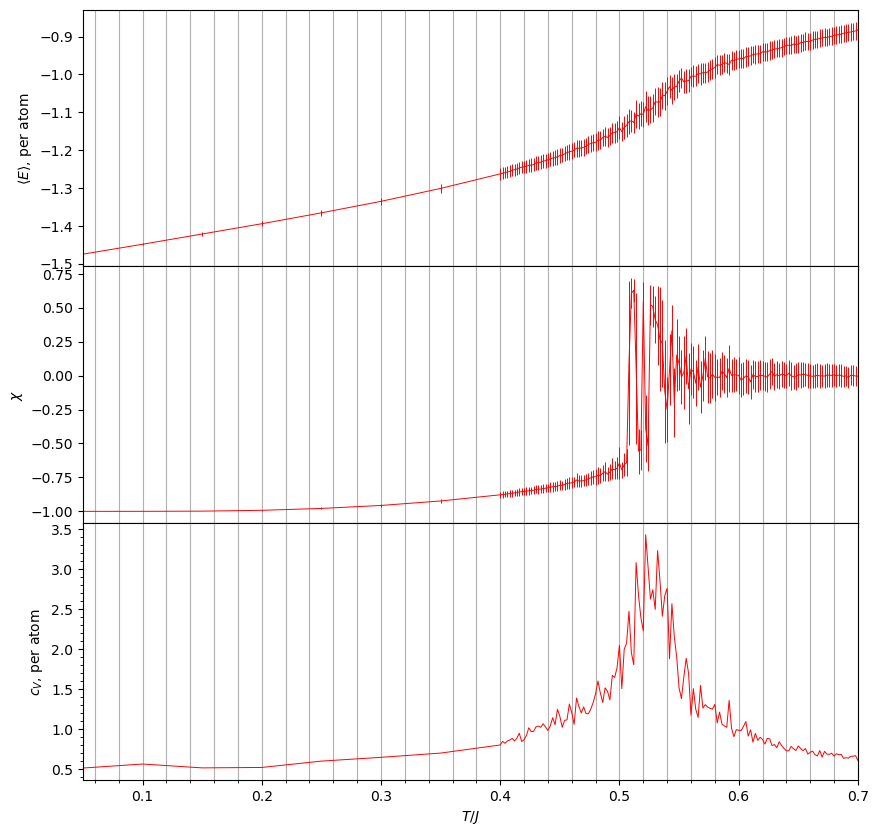

In [43]:
L1 = L2 = 24
E = zeros(n_cycles, length(T_range))
χ = zeros(n_cycles, length(T_range))
read!("heisenberg_T_scan_L$(L1)_zoomedin_E.dat", E)
read!("heisenberg_T_scan_L$(L1)_zoomedin_chi.dat", χ)

E_avg = [mean(E[:, n]) for n in 1:length(T_range)]
E_var = [std(E[:, n]) for n in 1:length(T_range)]

χ_avg = [mean(χ[:, n]) for n in 1:length(T_range)]
χ_var = [std(χ[:, n]) for n in 1:length(T_range)]

E2_avg = [mean(E[:, n] .^ 2) for n in 1:length(T_range)]
cV = (E2_avg - (E_avg .^ 2)) ./ (collect(T_range) .^ 2)

plt.figure(figsize=(10,10))
gs = plt.matplotlib.gridspec.GridSpec(3, 1, hspace=0)

ax1 = plt.subplot(gs[1])
ax1.errorbar(collect(T_range), E_avg / (L1 * L2), yerr=E_var / (L1 * L2), lw=0.7, color="red")
ax1.set_ylabel(raw"$\langle E\rangle$, per atom")
plt.setp(ax1.get_xticklabels(), visible=false)
ax1.grid(axis="x", which="both")

ax2 = plt.subplot(gs[2], sharex=ax1)
ax2.errorbar(collect(T_range), χ_avg, yerr=χ_var, lw=0.7, color="red")
ax2.set_ylabel(raw"$\chi$")
plt.setp(ax2.get_xticklabels(), visible=false)
ax2.grid(axis="x", which="both")

ax3 = plt.subplot(gs[3], sharex=ax1)
ax3.plot(collect(T_range), cV / (L1 * L2), lw=0.7, color="red")
ax3.set_ylabel(raw"$c_V$, per atom")
ax3.grid(axis="x", which="both")

ax3.set_xlim((first(T_range), last(T_range)))
ax3.set_xlabel(raw"$T/J$")
ax3.minorticks_on()
plt.show()

plt.savefig("heisenberg_phase_trans.pdf")

# Reweighting

In [44]:
function reweight(E::Array{Float64, 2}, O::Array{Float64, 2}, T_range, i_ref, i)
    β_ref = 1 / T_range[i_ref]
    β = 1 / T_range[i]
    Δβ = β - β_ref
    E0 = minimum(E[:, i_ref])
    w = exp.(-Δβ * (E[:, i_ref] .- E0))
    return sum(O[:, i_ref] .* w) / sum(w)
end

reweight (generic function with 1 method)

sys:1: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


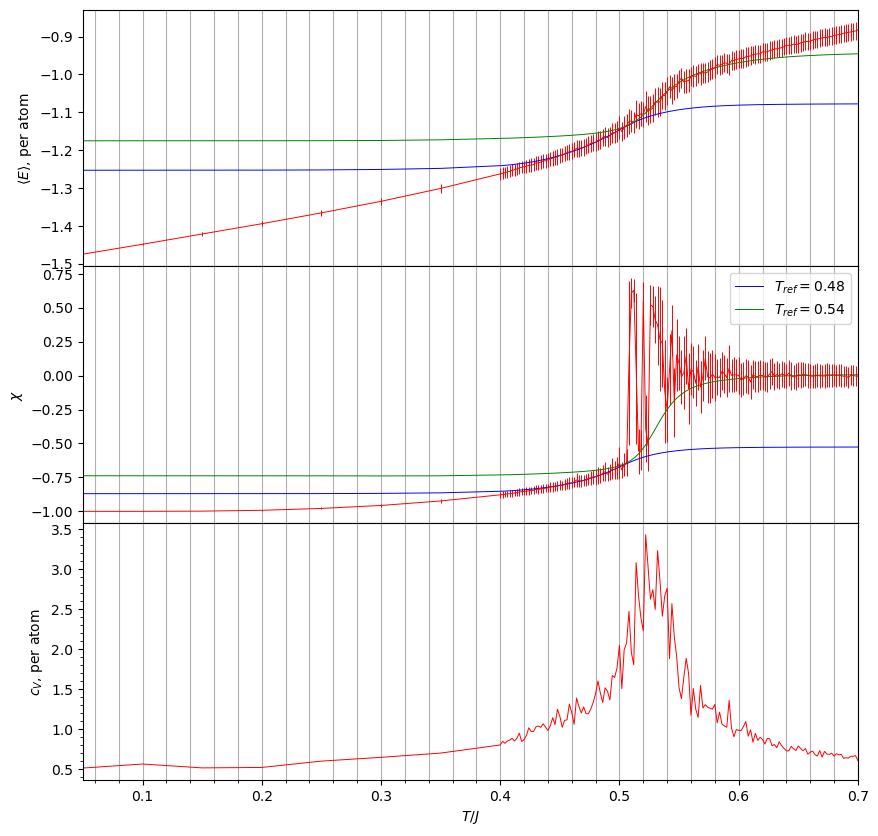

In [45]:
L1 = L2 = 24
E = zeros(n_cycles, length(T_range))
χ = zeros(n_cycles, length(T_range))
read!("heisenberg_T_scan_L$(L1)_zoomedin_E.dat", E)
read!("heisenberg_T_scan_L$(L1)_zoomedin_chi.dat", χ)

E_avg = [mean(E[:, n]) for n in 1:length(T_range)]
E_var = [std(E[:, n]) for n in 1:length(T_range)]

χ_avg = [mean(χ[:, n]) for n in 1:length(T_range)]
χ_var = [std(χ[:, n]) for n in 1:length(T_range)]

E2_avg = [mean(E[:, n] .^ 2) for n in 1:length(T_range)]
cV = (E2_avg - (E_avg .^ 2)) ./ (collect(T_range) .^ 2)

plt.figure(figsize=(10,10))
gs = plt.matplotlib.gridspec.GridSpec(3, 1, hspace=0)

ax1 = plt.subplot(gs[1])
ax1.errorbar(collect(T_range), E_avg / (L1 * L2), yerr=E_var / (L1 * L2), lw=0.7, color="red")
ax1.plot(collect(T_range), [reweight(E, E / (L1 * L2), T_range, 48, i) for i in eachindex(T_range)], lw=0.7, color="blue", label="\$T_{ref}=$(T_range[48])\$")
ax1.plot(collect(T_range), [reweight(E, E / (L1 * L2), T_range, 78, i) for i in eachindex(T_range)], lw=0.7, color="green", label="\$T_{ref}=$(T_range[78])\$")
ax1.set_ylabel(raw"$\langle E\rangle$, per atom")
plt.setp(ax1.get_xticklabels(), visible=false)
ax1.grid(axis="x", which="both")
ax2.legend()

ax2 = plt.subplot(gs[2], sharex=ax1)
ax2.errorbar(collect(T_range), χ_avg, yerr=χ_var, lw=0.7, color="red")
ax2.plot(collect(T_range), [reweight(E, χ, T_range, 48, i) for i in eachindex(T_range)], lw=0.7, color="blue", label="\$T_{ref}=$(T_range[48])\$")
ax2.plot(collect(T_range), [reweight(E, χ, T_range, 78, i) for i in eachindex(T_range)], lw=0.7, color="green", label="\$T_{ref}=$(T_range[78])\$")
ax2.legend()

ax2.set_ylabel(raw"$\chi$")
plt.setp(ax2.get_xticklabels(), visible=false)
ax2.grid(axis="x", which="both")

ax3 = plt.subplot(gs[3], sharex=ax1)
ax3.plot(collect(T_range), cV / (L1 * L2), lw=0.7, color="red")
ax3.set_ylabel(raw"$c_V$, per atom")
ax3.grid(axis="x", which="both")

ax3.set_xlim((first(T_range), last(T_range)))
ax3.set_xlabel(raw"$T/J$")
ax3.minorticks_on()
plt.show()

plt.savefig("heisenberg_phase_trans.pdf")

# Autocorrelation time

In [94]:
using StatsBase: autocor
using CurveFit: exp_fit

function autocorr_time(x; lags = 0:200)
    ac = autocor(x, lags)
    a, b = exp_fit(1:length(ac), ac)
    return -1 / b
end

autocorr_time (generic function with 2 methods)

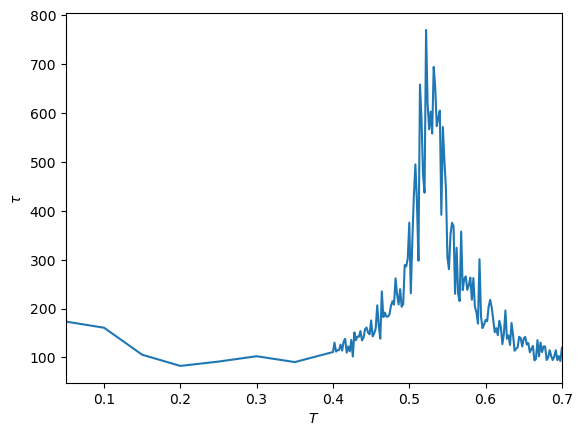

In [95]:
E = zeros(n_cycles, length(T_range))
read!("heisenberg_T_scan_L$(L1)_zoomedin_E.dat", E)
τ_list = [autocorr_time(E[:, i]) for i in 1:size(E, 2)]
plt.plot(T_range, τ_list)

plt.xlim((first(T_range), last(T_range)))
plt.xlabel(raw"$T$");
plt.ylabel(raw"$\tau$");

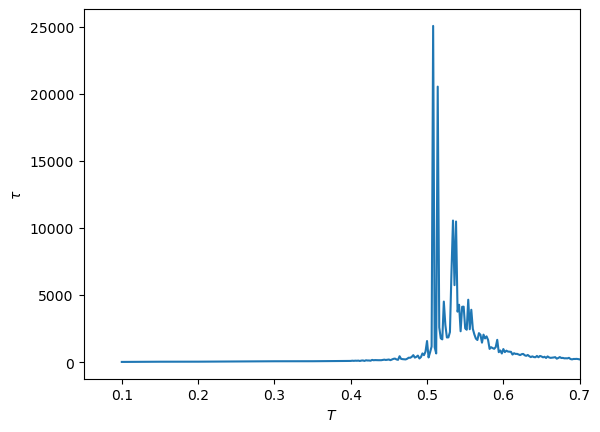

In [96]:
χ = zeros(n_cycles, length(T_range))
read!("heisenberg_T_scan_L$(L1)_zoomedin_chi.dat", χ)
τ_list = [autocorr_time(χ[:, i], lags=0:150) for i in 1:size(E, 2)]
plt.plot(T_range, τ_list)

plt.xlim((first(T_range), last(T_range)))
plt.xlabel(raw"$T$");
plt.ylabel(raw"$\tau$");